# Spotify Music Trends Analysis

## Objective
Describe release-era differences in this catalog using Pandas, SQL, visual exploration, and a pre-specified artist-level statistical comparison. Separate sample descriptions from population and causal claims.

## Dataset overview
The source is Yamac Eren Ay's [Spotify Dataset 1921–2020, 600k+ Tracks](https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks)
The actual release-year range is audited below rather than inferred from the title. This is a historical catalog snapshot with track metadata, Spotify audio descriptors, and popularity (0–100). It has no track-level genre, album, listener histories, or contemporaneous chart labels.

Run `python scripts/download_data.py` and `python scripts/prepare_data.py` first. Every notebook runs independently from the project root. Source hashes and cleaning counts live in `data/processed/quality_report.json`.

## Imports

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "scripts/prepare_data.py").exists():
    raise RuntimeError("Open Jupyter from the project root.")
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
pd.set_option("display.max_columns", 15)
assert Path(sys.prefix).name == "spotify", "Select the Python (spotify) kernel."
display(Markdown(f"**Runtime:** Python {platform.python_version()} · spotify environment"))
AUDIO_FEATURES = ["danceability", "energy", "valence", "acousticness",
                  "instrumentalness", "speechiness", "liveness", "loudness", "tempo"]

**Runtime:** Python 3.14.7 · spotify environment

## Data loading and cleaning

In [2]:
tracks = pd.read_parquet(ROOT / "data/processed/tracks.parquet")
quality = json.loads((ROOT / "data/processed/quality_report.json").read_text())
display(pd.Series({"raw_rows": quality["raw_rows"],
                   "processed_rows": len(tracks),
                   "first_year": quality["year_min"], "last_year": quality["year_max"],
                   "repeated_artist_title_rows": quality["repeated_artist_title_rows"]}, name="Data audit"))
assert tracks.id.is_unique

raw_rows                      586672
processed_rows                586601
first_year                      1900
last_year                       2021
repeated_artist_title_rows     62393
Name: Data audit, dtype: int64

Shared preparation removes exact duplicates and repeated Spotify IDs, and drops rows without usable identity. Invalid numeric values become missing; unknown zero tempo becomes missing. Dates keep their original precision in `release_date`, with a derived year for grouping. Long recordings are flagged, not arbitrarily deleted. Unicode names are retained. Distinct IDs with the same artist/title remain in the shared data because editions can differ; modeling and recommendation apply stricter deduplication below. Unobserved recordings cannot be identified without acoustic fingerprints.

## Exploratory data analysis
Start with scale, missingness, and the distribution of the available measurements.

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,loudness,tempo,duration_min,popularity
count,586601.000,586601.000,586601.000,586601.000,586601.000,586601.000,586601.000,586601.000,586273.000,586601.000,586601.000
mean,0.564,0.542,0.552,0.450,0.113,0.105,0.214,-10.206,118.534,3.834,27.573
std,0.166,0.252,0.258,0.349,0.267,0.180,0.184,5.089,29.639,2.109,18.369
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-60.000,30.506,0.056,0.000
25%,0.453,0.343,0.346,0.097,0.000,0.034,0.098,-12.891,95.655,2.918,13.000
50%,0.577,0.549,0.564,0.422,0.000,0.044,0.139,-9.242,117.422,3.582,27.000
75%,0.686,0.748,0.769,0.784,0.010,0.076,0.278,-6.481,136.340,4.398,41.000
max,0.991,1.000,1.000,0.996,1.000,0.971,1.000,5.376,246.381,93.687,100.000


danceability          0
energy                0
valence               0
acousticness          0
instrumentalness      0
speechiness           0
liveness              0
loudness              0
tempo               328
year                  0
popularity            0
Name: Missing values, dtype: int64

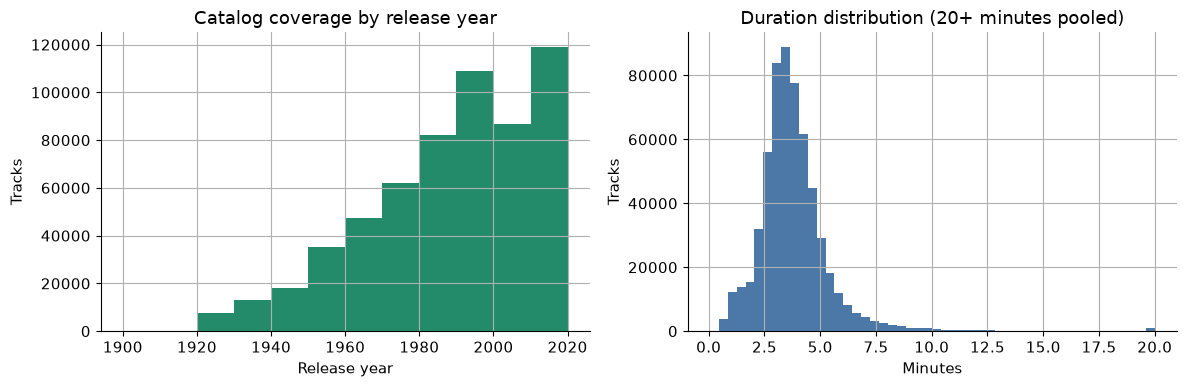

In [3]:
display(tracks[AUDIO_FEATURES + ["duration_min", "popularity"]].describe().round(3))
display(tracks[AUDIO_FEATURES + ["year", "popularity"]].isna().sum().rename("Missing values"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tracks.year.hist(bins=np.arange(1900, 2030, 10), ax=axes[0], color="#238b69")
axes[0].set(title="Catalog coverage by release year", xlabel="Release year", ylabel="Tracks")
tracks.duration_min.clip(upper=20).hist(bins=50, ax=axes[1], color="#4c78a8")
axes[1].set(title="Duration distribution (20+ minutes pooled)", xlabel="Minutes", ylabel="Tracks")
fig.tight_layout()
fig.savefig(REPORTS / "01_coverage.png", dpi=120)
plt.show()

The catalog is not a random sample of all music released. Changes in coverage can alter apparent trends. The duration plot pools the long tail for readability; the underlying observations remain unchanged.

## SQL and feature engineering
DuckDB groups the full track table by decade. Medians resist extreme recording lengths; averages describe typical audio-feature levels. A matching Pandas aggregation checks the SQL result.

In [4]:
import duckdb
connection = duckdb.connect()
connection.register("tracks", tracks)
decades = connection.sql('''
    SELECT decade, COUNT(*) AS track_count,
           MEDIAN(duration_min) AS median_minutes,
           AVG(energy) AS energy, AVG(acousticness) AS acousticness,
           AVG(danceability) AS danceability, AVG(popularity) AS popularity
    FROM tracks WHERE decade IS NOT NULL
    GROUP BY decade ORDER BY decade
''').df()
pandas_counts = tracks.groupby("decade").size().to_numpy()
np.testing.assert_array_equal(decades.track_count.to_numpy(), pandas_counts)
display(decades.round(3))
connection.close()

,decade,track_count,median_minutes,energy,acousticness,danceability,popularity
0,1900,1,3.899,0.791,0.139,0.659,19.000
1,1920,7592,2.936,0.281,0.890,0.605,1.142
2,1930,13024,3.046,0.306,0.870,0.551,2.110
3,1940,18021,3.099,0.268,0.915,0.476,1.783
4,1950,35363,3.082,0.299,0.841,0.483,8.392
5,1960,47262,2.951,0.405,0.682,0.497,17.902
6,1970,61840,3.486,0.502,0.500,0.524,24.167
7,1980,82322,3.728,0.550,0.407,0.563,25.678
8,1990,108872,3.900,0.574,0.367,0.572,29.461
9,2000,86841,3.904,0.649,0.313,0.590,36.628


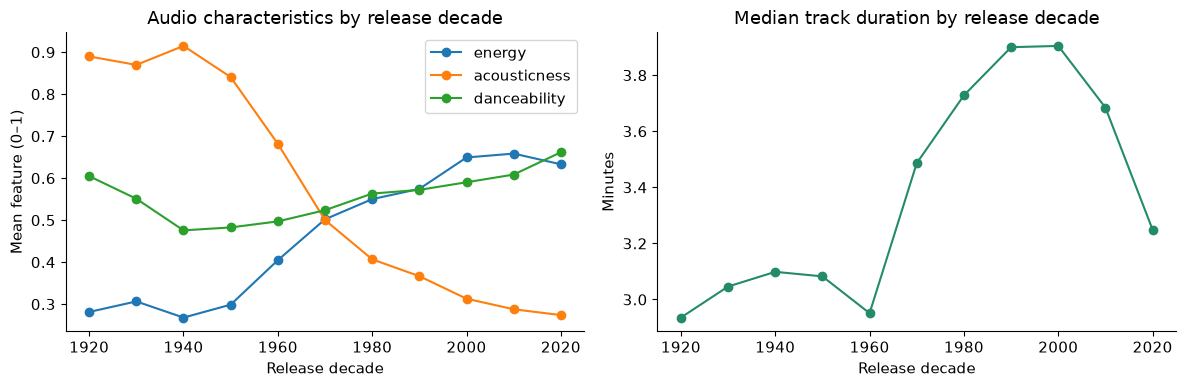

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_decades = decades.loc[decades.track_count >= 100]
for feature in ["energy", "acousticness", "danceability"]:
    axes[0].plot(plot_decades.decade, plot_decades[feature], marker="o", label=feature)
axes[0].set(title="Audio characteristics by release decade", xlabel="Release decade", ylabel="Mean feature (0–1)")
axes[0].legend()
axes[1].plot(plot_decades.decade, plot_decades.median_minutes, marker="o", color="#238b69")
axes[1].set(title="Median track duration by release decade", xlabel="Release decade", ylabel="Minutes")
fig.tight_layout()
fig.savefig(REPORTS / "01_trends.png", dpi=120)
plt.show()

The chart shows only decades with at least 100 tracks; the SQL table retains every decade for audit. Acousticness falls markedly from the 1940s onward while energy rises. Median durations peak around the 1990s–2000s before declining. The 2020s include only 2020–2021 and must not be read as a complete decade. Release dates may describe reissues rather than original recordings, so these curves are catalog summaries, not a history of musical innovation.

artist
Die drei ???                          3856
TKKG Retro-Archiv                     2006
Benjamin Blümchen                     1503
Bibi Blocksberg                       1472
Lata Mangeshkar                       1373
Bibi und Tina                          927
Tintin; Tomas Bolme; Bert-Åke Varg     905
Francisco Canaro                       891
Ella Fitzgerald                        870
Tadeusz Dolega Mostowicz               838
Name: Tracks in catalog, dtype: int64

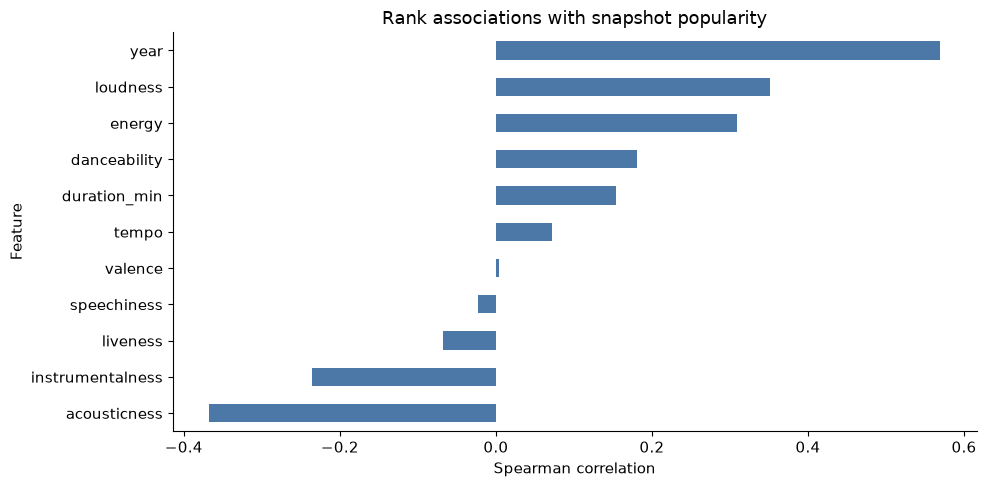

In [6]:
artist_counts = tracks.groupby("artist").size().sort_values(ascending=False).head(10)
display(artist_counts.rename("Tracks in catalog"))
correlations = tracks[AUDIO_FEATURES + ["duration_min", "year", "popularity"]].corr(method="spearman")["popularity"].drop("popularity").sort_values()
ax = correlations.plot.barh(color="#4c78a8")
ax.set(title="Rank associations with snapshot popularity", xlabel="Spearman correlation", ylabel="Feature")
plt.tight_layout()
plt.show()

Spearman correlation measures monotonic association using ranks. An association with release year can reflect recency, catalog selection, or survivorship. Frequent artists are frequent in this dataset; that does not establish streaming market share.

## Statistical methodology: paired artist comparison
We pre-specify one comparison: mean energy in the 2010s versus the 1980s among artists represented in both decades. First deduplicate artist/title editions; then average within primary artist and decade. A paired t-test asks whether the mean within-artist change is zero. A 95% t confidence interval estimates uncertainty across these artists, weighting each artist equally. This reduces track-level pseudoreplication but does not remove collaboration, selection, or reissue bias. It is an exploratory, conditional interval, not a probability-sample population estimate.

paired_artists                1.200000e+03
mean_energy_change            4.907585e-02
ci_low                        3.870581e-02
ci_high                       5.944588e-02
p_value                       7.357958e-20
standardized_paired_effect    2.680301e-01
Name: 2010s minus 1980s, dtype: float64

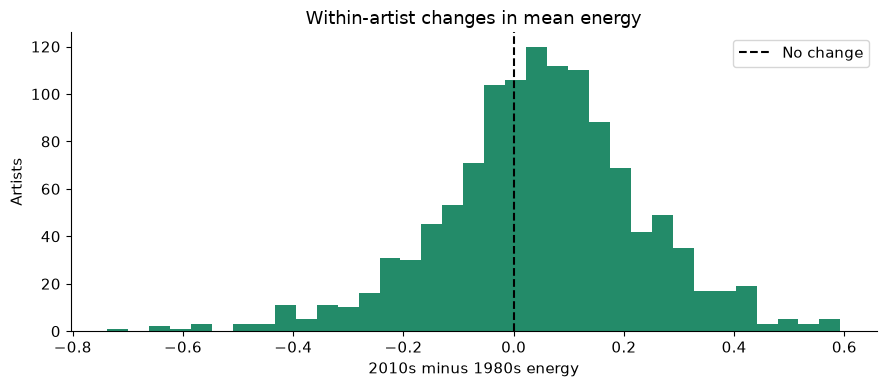

**Result:** Across 1,200 paired artists, mean energy changed by **0.049**, with a 95% interval of **[0.039, 0.059]**. The p-value is **7.36e-20**. Interpret magnitude and interval alongside the assumptions, rather than treating statistical significance as musical importance.

In [7]:
from scipy import stats
unique_recordings = tracks.drop_duplicates("recording_group")
artist_eras = unique_recordings.loc[unique_recordings.decade.isin([1980, 2010])].pivot_table(
    index="primary_artist_id", columns="decade", values="energy", aggfunc="mean")
paired = artist_eras.dropna()
changes = paired[2010] - paired[1980]
test = stats.ttest_rel(paired[2010], paired[1980])
interval = stats.t.interval(0.95, df=len(changes)-1, loc=changes.mean(), scale=stats.sem(changes))
comparison = {"paired_artists": len(changes), "mean_energy_change": float(changes.mean()),
              "ci_low": float(interval[0]), "ci_high": float(interval[1]),
              "p_value": float(test.pvalue), "standardized_paired_effect": float(changes.mean()/changes.std())}
display(pd.Series(comparison, name="2010s minus 1980s"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(changes, bins=35, color="#238b69")
ax.axvline(0, color="black", linestyle="--", label="No change")
ax.set(title="Within-artist changes in mean energy", xlabel="2010s minus 1980s energy", ylabel="Artists")
ax.legend()
plt.tight_layout()
plt.show()
(REPORTS / "trends_metrics.json").write_text(json.dumps(comparison, indent=2))
display(Markdown(f"**Result:** Across {len(changes):,} paired artists, mean energy changed by **{changes.mean():.3f}**, with a 95% interval of **[{interval[0]:.3f}, {interval[1]:.3f}]**. The p-value is **{test.pvalue:.3g}**. Interpret magnitude and interval alongside the assumptions, rather than treating statistical significance as musical importance."))

## Interpretation, limitations, and conclusion
The release-decade summaries and within-artist comparison answer different questions: the first mixes changes in artists with changes within artists; the second conditions on long-lived catalog representation. Neither identifies a causal effect of time. Popularity was observed at a single collection snapshot, not at release, and missing listening counts prevent an analysis of actual consumption trends. Genre trends are unavailable because this track table has no genre labels. A next study should use dated chart or listening observations and verified original release dates.